# Plot nominal satellite tracks

This example loads nominal tracks bundled with SatPass, selects the tracks crossing a geographic domain, and plots them.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, '../src')

import matplotlib.pyplot as plt
import satpass

print(f"SatPass version: {satpass.__version__}")

SatPass version: 0.1.0


## Select a mission and geographic domain

The domain format is `[longitude_min, longitude_max, latitude_min, latitude_max]` in degrees.

In [2]:
mission = "sw" 
domain = [150.0, 160.0, -55.0, -50.0]

## Load and select nominal tracks

In [3]:
nominal = satpass.NominalTrack(mission)
tracks = nominal.select_in_area(
    domain, extend_to_latitude_bounds=False)

print(f"Mission: {nominal.meta['full_name']}")
print(f"Total nominal points: {len(nominal.nominal):,}")
print(f"Selected tracks: {tracks['track'].nunique()}")
print(f"Selected points: {len(tracks):,}")

tracks.head()

Mission: SWOT
Total nominal points: 181,396
Selected tracks: 18
Selected points: 148


,track,lon,lat,lon0_360,subcycle,direction
1174,4,152.861965,-50.252203,153.994863,3.0,des
1175,4,153.127189,-50.799775,153.994863,3.0,des
1176,4,153.399646,-51.346459,153.994863,3.0,des
1177,4,153.679639,-51.892219,153.994863,3.0,des
1178,4,153.967489,-52.437018,153.994863,3.0,des


In [4]:
tracks

,track,lon,lat,lon0_360,subcycle,direction
1174,4,152.861965,-50.252203,153.994863,3.0,des
1175,4,153.127189,-50.799775,153.994863,3.0,des
1176,4,153.399646,-51.346459,153.994863,3.0,des
1177,4,153.679639,-51.892219,153.994863,3.0,des
1178,4,153.967489,-52.437018,153.994863,3.0,des
...,...,...,...,...,...,...
173878,560,156.606904,-52.758559,156.493616,3.0,des
173879,560,156.907982,-53.301726,156.493616,3.0,des
173880,560,157.217835,-53.843825,156.493616,3.0,des
173881,560,157.536854,-54.384808,156.493616,3.0,des


## Plot the selected tracks

Blue tracks are ascending and orange tracks are descending.

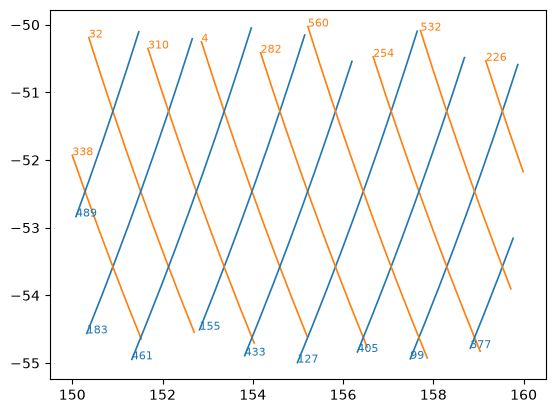

In [5]:
colors = {"asc": "tab:blue", "des": "tab:orange"}

ax = plt.subplot()

for idx, track in tracks.groupby('track'):
    # plt.plot(track['lon'], track['lat'], label=f"Track {idx}")
    direction = track["direction"].iloc[0]
    c=  colors.get(direction, "0.5")
    ax.plot(
        track["lon"],
        track["lat"],
        color=c,
        linewidth=1.2,
        label=direction,
    )
    plt.text(track["lon"].iloc[0], track["lat"].iloc[0], f"{idx}", fontsize=8, color=c)

#### Plot nominal tracks different missions, jason-3 in orange, Swot in blue

In [6]:
nominal = satpass.NominalTrack('j3')
tracks_j3 = nominal.select_in_area(
    domain, extend_to_latitude_bounds=False)

nominal = satpass.NominalTrack('sw')
tracks_sw = nominal.select_in_area(
    domain, extend_to_latitude_bounds=False)

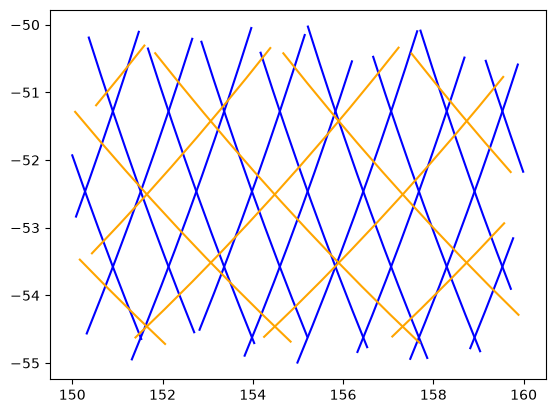

In [7]:
for idx, track in tracks_sw.groupby('track'):
    plt.plot(track['lon'], track['lat'], c = 'b')

for idx, track in tracks_j3.groupby('track'):
    plt.plot(track['lon'], track['lat'], c = 'orange')